In [177]:
#%pip install tensorflow

In [178]:
import tensorflow as tf

In [ ]:
# Use previously stored files
english_file = "../data/preprocessed_10_percent.en"
dutch_file = "../data/preprocessed_10_percent.nl"

# Store the sentences in pairs for convenience of random shuffling 
sentence_pairs = []
# Read the English and Dutch sentences
with open(english_file, "r", encoding="utf-8") as english_data:
    with open(dutch_file, "r", encoding="utf-8") as dutch_data:
        for english_line, dutch_line in zip(english_data, dutch_data):
            # Remove the newlines
            english_sentence = english_line.strip()
            dutch_sentence = dutch_line.strip()
            sentence_pairs.append((english_sentence, dutch_sentence))

In [180]:
import random

random.seed(42)

# Randomly shuffle the order of the sentence pairs
random.shuffle(sentence_pairs)

# Compute the splits
total_size = len(sentence_pairs)
test_size = int(total_size * 0.20)
validation_size = int(total_size * 0.10)
training_size = total_size - test_size - validation_size

# Create the splited datasets
training_pairs = sentence_pairs[:training_size]

validation_pairs = sentence_pairs[training_size:training_size + validation_size]

test_pairs = sentence_pairs[training_size + validation_size:]
# Check the splits #
print("Training pairs:", len(training_pairs))
print("Validation pairs:", len(validation_pairs))
print("Test pairs:", len(test_pairs))

Training pairs: 138498
Validation pairs: 19785
Test pairs: 39570


In [181]:
maximum_english_length = 55
maximum_dutch_length = 57

In [182]:
def process_sentences(sentence_pairs):
    """Process sentences by adding markers before and after the target Dutch sentences so that they become indicators for the decoder"""
    english_sentences = []
    dutch_sentences = []
    for english_sentence, dutch_sentence in sentence_pairs:
        english_sentences.append(english_sentence)
        # Add markers
        marked_dutch_sentence = "startmark " + dutch_sentence + " endmark"
        dutch_sentences.append(marked_dutch_sentence)
    return english_sentences, dutch_sentences

In [183]:
training_english, training_dutch = process_sentences(training_pairs)
validation_english, validation_dutch = process_sentences(validation_pairs)
test_english, test_dutch = process_sentences(test_pairs)

In [184]:
# Limit each language vocabulary to its most frequent words
maximum_vocabulary_size = 20000

# Create English vectorizer 
english_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=maximum_vocabulary_size,
    standardize=None,
    split="whitespace",
    output_mode="int",
    output_sequence_length=maximum_english_length
)

# Create the Dutch vectorizer
dutch_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=maximum_vocabulary_size,
    standardize=None,
    split="whitespace",
    output_mode="int",
    output_sequence_length=maximum_dutch_length
)

In [185]:
# Learn the English vocabulary from the trainings
english_vectorizer.adapt(training_english)

# Learn the Dutch vocabulary from the trainings
dutch_vectorizer.adapt(training_dutch)

# Store the actual vocabulary sizes
english_vocabulary_size = len(english_vectorizer.get_vocabulary())
dutch_vocabulary_size = len(dutch_vectorizer.get_vocabulary())

# print("English vocabulary size:", english_vocabulary_size)
# print("Dutch vocabulary size:", dutch_vocabulary_size)

In [186]:
# Convert the English training sentences into id sequence
training_encoder_inputs = english_vectorizer(training_english)

# Convert the marked Dutch training sentences into id sequence
training_dutch_sequences = dutch_vectorizer(training_dutch)

# Remove endmark because nothing after endmark needs to be predicted
training_decoder_inputs = training_dutch_sequences[:, :-1]

# Remove startmark because it doesn't need to predict startmark
training_decoder_targets = training_dutch_sequences[:, 1:]

In [187]:
# Same process for validation set
validation_encoder_inputs = english_vectorizer(validation_english)
validation_dutch_sequences = dutch_vectorizer(validation_dutch)
validation_decoder_inputs = validation_dutch_sequences[:, :-1]
validation_decoder_targets = validation_dutch_sequences[:, 1:]

In [188]:
# Use smaller fixed subsets while tuning the model
# Because tuning using entire training and validation set is too time costly
# tuning_training_size = 20000
# tuning_validation_size = 3000

# tuning_training_encoder = training_encoder_inputs[:tuning_training_size]
# tuning_training_decoder_inputs = training_decoder_inputs[:tuning_training_size]
# tuning_training_targets = training_decoder_targets[:tuning_training_size]

# tuning_validation_encoder = validation_encoder_inputs[:tuning_validation_size]
# tuning_validation_decoder_inputs = validation_decoder_inputs[:tuning_validation_size]
# tuning_validation_targets = validation_decoder_targets[:tuning_validation_size]

In [189]:
# Start each experiment with a fresh model
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

embedding_size = 128
hidden_size = 256

In [190]:
# The encoder receives an English id sequence
encoder_input = tf.keras.Input(shape=(maximum_english_length,), name="encoder_input")

# Convert English id sequence into embeddings
encoder_embedding_layer = tf.keras.layers.Embedding(
    input_dim=english_vocabulary_size,
    output_dim=embedding_size,
    trainable=True,
    mask_zero=True,
    name="encoder_embedding"
)

encoder_embedded = encoder_embedding_layer(encoder_input)

# Process the English sequence and return its final hidden state
encoder_gru_layer = tf.keras.layers.GRU(hidden_size, return_state=True, name="encoder_gru")

encoder_output, encoder_state = encoder_gru_layer(encoder_embedded)

In [191]:
# The decoder sequence
decoder_input = tf.keras.Input(shape=(maximum_dutch_length - 1,),name="decoder_input")

# Convert Dutch id sequence into embeddings
decoder_embedding_layer = tf.keras.layers.Embedding(
    input_dim=dutch_vocabulary_size,
    output_dim=embedding_size,
    trainable=True,
    mask_zero=True,
    name="decoder_embedding"
)

decoder_embedded = decoder_embedding_layer(decoder_input)

# Initialize the decoder using the encoder's final state.
decoder_gru_layer = tf.keras.layers.GRU(
    hidden_size,
    return_sequences=True,
    return_state=True,
    name="decoder_gru"
)

decoder_output, decoder_state = decoder_gru_layer(decoder_embedded, initial_state=encoder_state)

# Produce one score for every possible Dutch word
decoder_output_layer = tf.keras.layers.Dense(dutch_vocabulary_size, name="word_predictions")

word_predictions = decoder_output_layer(decoder_output)

In [192]:
# Initialize the translation model
translation_model = tf.keras.Model(inputs=[encoder_input, decoder_input], outputs=word_predictions)

In [193]:
# Use Adam optimizer to adjust model weights to reduce errors
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.002,
    clipnorm=1.0
)

# Connect the model to the training configuration
translation_model.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="word_accuracy"
        )
    ]
)

In [194]:
# Triggers early stopping callback if validation loss is no longer improving
final_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True
)
# Saves best model weights to a file
final_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "final_en_to_nl.weights.h5",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True
)

In [195]:
# Runs this for tuning the model
# training_history = translation_model.fit(
#     [
#         tuning_training_encoder,
#         tuning_training_decoder_inputs
#     ],
#     tuning_training_targets,
#     validation_data=(
#         [
#             tuning_validation_encoder,
#             tuning_validation_decoder_inputs
#         ],
#         tuning_validation_targets
#     ),

#     batch_size=batch_size,
#     epochs=maximum_epochs,
#     callbacks=[
#         early_stopping,
#     ]
# )

In [209]:
# Trains the model using entire training and validation set
final_en_to_nl_history = translation_model.fit(
    [
        training_encoder_inputs,
        training_decoder_inputs
    ],
    training_decoder_targets,
    validation_data=(
        [
            validation_encoder_inputs,
            validation_decoder_inputs
        ],
        validation_decoder_targets
    ),

    batch_size=32,
    epochs=5,
    callbacks=[
        final_early_stopping,
        final_checkpoint
    ]
)

In [231]:
# Use the best weights stored for evaluation & no need to run the training
translation_model.load_weights(
    "final_en_to_nl.weights.h5"
)

In [232]:
# %pip install sacrebleu

In [233]:
from sacrebleu.metrics import BLEU, CHRF
# BLEU evaluates how many words and short word sequences in the model translation also appear in the correct human translation
# CHRF compares translations using character sequences instead of only complete words

In [234]:
# The encoder converts an English sentence into its final state
encoder_inference_model = tf.keras.Model(
    inputs=encoder_input,
    outputs=encoder_state
)
# Inputs needed to generate one Dutch word at a time
decoder_word_input = tf.keras.Input(
    shape=(1,),
    dtype="int64"
)

decoder_state_input = tf.keras.Input(
    shape=(hidden_size,)
)

# Reuse the trained decoder layers.
decoder_word_embedding = decoder_embedding_layer(
    decoder_word_input
)
decoder_step_output, decoder_next_state = decoder_gru_layer(
    decoder_word_embedding,
    initial_state=decoder_state_input
)
decoder_word_scores = decoder_output_layer(
    decoder_step_output
)
decoder_inference_model = tf.keras.Model(
    inputs=[decoder_word_input, decoder_state_input],
    outputs=[decoder_word_scores, decoder_next_state]
)

In [235]:
dutch_vocabulary = dutch_vectorizer.get_vocabulary()

start_token_id = dutch_vocabulary.index("startmark")
end_token_id = dutch_vocabulary.index("endmark")

# Translate function
def translate_sentences(english_sentences):
    english_sequences = english_vectorizer(english_sentences)
    decoder_states = encoder_inference_model(english_sequences, training=False)
    number_of_sentences = len(english_sentences)
    current_words = tf.fill([number_of_sentences, 1], tf.constant(start_token_id, dtype=tf.int64))

    generated_word_ids = []
    for step in range(maximum_dutch_length - 1):
        word_scores, decoder_states = decoder_inference_model([current_words, decoder_states], training=False)
        next_word_ids = tf.argmax(word_scores[:, 0, :], axis=-1, output_type=tf.int64)
        generated_word_ids.append(next_word_ids.numpy())
        current_words = tf.expand_dims(next_word_ids, axis=1)

    translations = []

    for sentence_number in range(number_of_sentences):
        translated_words = []
        for step in range(len(generated_word_ids)):
            word_id = int(generated_word_ids[step][sentence_number])
            if word_id == end_token_id or word_id == 0:
                break
            translated_words.append(dutch_vocabulary[word_id])
        translations.append(" ".join(translated_words))
    return translations

In [238]:
# Translate the test set
test_predictions = []

evaluation_batch_size = 500
start_position = 0

while start_position < len(test_english):
    end_position = min(start_position + evaluation_batch_size, len(test_english))
    batch_sentences = test_english[start_position:end_position]
    batch_predictions = translate_sentences(batch_sentences)
    test_predictions.extend(batch_predictions)
    print("Translated", end_position, "of", len(test_english))
    start_position = end_position

In [239]:
# Evaluation for the entire test set
test_references = []

for sentence in test_dutch:
    sentence_words = sentence.split()
    reference_sentence = " ".join(
        sentence_words[1:-1]
    )
    test_references.append(
        reference_sentence
    )
test_bleu = BLEU().corpus_score(
    test_predictions,
    [test_references]
).score

test_chrf = CHRF().corpus_score(
    test_predictions,
    [test_references]
).score

print("Test BLEU:", round(test_bleu, 2))
print("Test chrF:", round(test_chrf, 2))

In [217]:
# Evaluation for fine tuning params
# evaluation_size = 500

# evaluation_english = validation_english[
#     :evaluation_size
# ]

# reference_translations = []

# for sentence in validation_dutch[:evaluation_size]:

#     sentence_words = sentence.split()

#     # Remove startmark and endmark.
#     reference_sentence = " ".join(
#         sentence_words[1:-1]
#     )
#     reference_translations.append(
#         reference_sentence
#     )

# predicted_translations = translate_sentences(
#     evaluation_english
# )

# bleu_metric = BLEU()
# chrf_metric = CHRF()

# bleu_score = bleu_metric.corpus_score(
#     predicted_translations,
#     [reference_translations]
# ).score

# chrf_score = chrf_metric.corpus_score(
#     predicted_translations,
#     [reference_translations]
# ).score

# print("Validation BLEU:", round(bleu_score, 2))
# print("Validation chrF:", round(chrf_score, 2))

In [ ]:
# #To observe the results
# for sentence_number in range(5):
#     print("English:")
#     print(evaluation_english[sentence_number])

#     print("Correct Dutch:")
#     print(reference_translations[sentence_number])

#     print("Model translation:")
#     print(predicted_translations[sentence_number])

#     print()

In [ ]:
# To observe the sample results from test evaluation
for sentence_number in range(5):
    print("English:")
    print(test_english[sentence_number])

    print("Correct Dutch:")
    print(test_references[sentence_number])

    print("Final model translation:")
    print(test_predictions[sentence_number])

    print()

In [ ]:
# short_predictions = []
# short_references = []

# medium_predictions = []
# medium_references = []

# long_predictions = []
# long_references = []


# for sentence_number in range(len(test_english)):
#     sentence_length = len(
#         test_english[sentence_number].split()
#     )
#     if sentence_length <= 10:
#         short_predictions.append(
#             test_predictions[sentence_number]
#         )
#         short_references.append(
#             test_references[sentence_number]
#         )

#     elif sentence_length <= 20:
#         medium_predictions.append(
#             test_predictions[sentence_number]
#         )
#         medium_references.append(
#             test_references[sentence_number]
#         )
#     else:
#         long_predictions.append(
#             test_predictions[sentence_number]
#         )
#         long_references.append(
#             test_references[sentence_number]
#         )

In [ ]:
# # How different lengths led to different results
# print("Short sentences:", len(short_predictions))
# print(
#     "BLEU:",
#     round(BLEU().corpus_score(
#         short_predictions,
#         [short_references]
#     ).score, 2)
# )
# print(
#     "chrF:",
#     round(CHRF().corpus_score(
#         short_predictions,
#         [short_references]
#     ).score, 2)
# )

# print("\nMedium sentences:", len(medium_predictions))
# print(
#     "BLEU:",
#     round(BLEU().corpus_score(
#         medium_predictions,
#         [medium_references]
#     ).score, 2)
# )
# print(
#     "chrF:",
#     round(CHRF().corpus_score(
#         medium_predictions,
#         [medium_references]
#     ).score, 2)
# )

# print("\nLong sentences:", len(long_predictions))
# print(
#     "BLEU:",
#     round(BLEU().corpus_score(
#         long_predictions,
#         [long_references]
#     ).score, 2)
# )
# print(
#     "chrF:",
#     round(CHRF().corpus_score(
#         long_predictions,
#         [long_references]
#     ).score, 2)
# )

In [ ]:
## Experiment 5 & 6: Word2Vec & FastText Embeddings
#%pip install gensim

In [ ]:
from gensim.models import Word2Vec
from gensim.models import FastText

import numpy as np
embeddings_english_sentences = []
embeddings_dutch_sentences = []

for sentence in training_english[:tuning_training_size]:
    embeddings_english_sentences.append(
        sentence.split()
    )
for sentence in training_dutch[:tuning_training_size]:
    embeddings_dutch_sentences.append(
        sentence.split()
    )

In [ ]:
# Use different embedding model
# english_word2vec = Word2Vec(
#     sentences=embeddings_english_sentences,
#     vector_size=128,
#     window=5,
#     min_count=1,
#     workers=1,
#     seed=42,
#     epochs=5
# )

# dutch_word2vec = Word2Vec(
#     sentences=embeddings_dutch_sentences,
#     vector_size=128,
#     window=5,
#     min_count=1,
#     workers=1,
#     seed=42,
#     epochs=5
# )
english_fasttext = FastText(
    sentences=embeddings_english_sentences,
    vector_size=128,
    window=5,
    min_count=1,
    workers=1,
    seed=42,
    epochs=5
)

dutch_fasttext = FastText(
    sentences=embeddings_dutch_sentences,
    vector_size=128,
    window=5,
    min_count=1,
    workers=1,
    seed=42,
    epochs=5
)

In [ ]:
# Similar step as the TextVectorisor
english_vocabulary = english_vectorizer.get_vocabulary()
dutch_vocabulary = dutch_vectorizer.get_vocabulary()

np.random.seed(42)

english_embedding_matrix = np.random.normal(
    0,
    0.05,
    (english_vocabulary_size, 128)
).astype("float32")

dutch_embedding_matrix = np.random.normal(
    0,
    0.05,
    (dutch_vocabulary_size, 128)
).astype("float32")

# The token with ID 0 is padding and should remain zero.
english_embedding_matrix[0] = 0
dutch_embedding_matrix[0] = 0

In [ ]:
# # Place each English Word2Vec vector at its matching vocabulary ID.
# for word_id in range(2, english_vocabulary_size):
#     word = english_vocabulary[word_id]
#     if word in english_word2vec.wv:
#         english_embedding_matrix[word_id] = (
#             english_word2vec.wv[word]
#         )
        
# # Place each Dutch Word2Vec vector at its matching vocabulary ID.
# for word_id in range(2, dutch_vocabulary_size):
#     word = dutch_vocabulary[word_id]
#     if word in dutch_word2vec.wv:
#         dutch_embedding_matrix[word_id] = (
#             dutch_word2vec.wv[word]
#         )

In [ ]:
# Place each English FastText vector at its matching vocabulary ID.
for word_id in range(2, english_vocabulary_size):
    word = english_vocabulary[word_id]
    english_embedding_matrix[word_id] = (
        english_fasttext.wv[word]
    )

# Place each Dutch FastText vector at its matching vocabulary ID.
for word_id in range(2, dutch_vocabulary_size):
    word = dutch_vocabulary[word_id]
    dutch_embedding_matrix[word_id] = (
        dutch_fasttext.wv[word]
    )

In [ ]:
# Building fresh new model using new embedding models
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# But using previously fine-tuned params
embedding_size = 128
hidden_size = 256

In [ ]:
encoder_input = tf.keras.Input(
    shape=(maximum_english_length,),
    name="encoder_input"
)

encoder_embedding_layer = tf.keras.layers.Embedding(
    input_dim=english_vocabulary_size,
    output_dim=embedding_size,
    weights=[english_embedding_matrix],
    trainable=True,
    mask_zero=True,
    name="encoder_fasttext_embedding"
)

encoder_embedded = encoder_embedding_layer(
    encoder_input
)

encoder_gru_layer = tf.keras.layers.GRU(
    hidden_size,
    return_state=True,
    name="encoder_gru"
)

encoder_output, encoder_state = encoder_gru_layer(
    encoder_embedded
)

In [ ]:
decoder_input = tf.keras.Input(
    shape=(maximum_dutch_length - 1,),
    name="decoder_input"
)
decoder_embedding_layer = tf.keras.layers.Embedding(
    input_dim=dutch_vocabulary_size,
    output_dim=embedding_size,
    weights=[dutch_embedding_matrix],
    trainable=True,
    mask_zero=True,
    name="decoder_fasttext_embedding"
)

decoder_embedded = decoder_embedding_layer(
    decoder_input
)

decoder_gru_layer = tf.keras.layers.GRU(
    hidden_size,
    return_sequences=True,
    return_state=True,
    name="decoder_gru"
)

decoder_output, decoder_state = decoder_gru_layer(
    decoder_embedded,
    initial_state=encoder_state
)

decoder_output_layer = tf.keras.layers.Dense(
    dutch_vocabulary_size,
    name="word_predictions"
)

word_predictions = decoder_output_layer(
    decoder_output
)

In [ ]:
translation_model = tf.keras.Model(
    inputs=[encoder_input, decoder_input],
    outputs=word_predictions
)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.002,
    clipnorm=1.0
)
translation_model.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="word_accuracy"
        )
    ]
)



In [ ]:
# # Use the trained Word2Vec or FastText encoder to obtain the English sentence state.
# encoder_inference_model = tf.keras.Model(
#     inputs=encoder_input,
#     outputs=encoder_state
# )

# # Inputs for generating one Dutch word.
# decoder_word_input = tf.keras.Input(
#     shape=(1,),
#     dtype="int64"
# )

# decoder_state_input = tf.keras.Input(
#     shape=(hidden_size,)
# )

# # Reuse the trained Word2Vec or FastText decoder layers.
# decoder_word_embedding = decoder_embedding_layer(
#     decoder_word_input
# )

# decoder_step_output, decoder_next_state = decoder_gru_layer(
#     decoder_word_embedding,
#     initial_state=decoder_state_input
# )

# decoder_word_scores = decoder_output_layer(
#     decoder_step_output
# )

# decoder_inference_model = tf.keras.Model(
#     inputs=[decoder_word_input, decoder_state_input],
#     outputs=[decoder_word_scores, decoder_next_state]
# )

In [ ]:
# Evaluation for different embedding models
# evaluation_size = 500

# evaluation_english = validation_english[
#     :evaluation_size
# ]

# reference_translations = []

# for sentence in validation_dutch[:evaluation_size]:

#     sentence_words = sentence.split()

#     # Remove startmark and endmark.
#     reference_sentence = " ".join(
#         sentence_words[1:-1]
#     )
#     reference_translations.append(
#         reference_sentence
#     )

# predicted_translations = translate_sentences(
#     evaluation_english
# )

# bleu_metric = BLEU()
# chrf_metric = CHRF()

# bleu_score = bleu_metric.corpus_score(
#     predicted_translations,
#     [reference_translations]
# ).score

# chrf_score = chrf_metric.corpus_score(
#     predicted_translations,
#     [reference_translations]
# ).score

# print("Validation BLEU:", round(bleu_score, 2))
# print("Validation chrF:", round(chrf_score, 2))

In [ ]:
# # To observe the results
# for sentence_number in range(5):

#     print("English:")
#     print(evaluation_english[sentence_number])

#     print("Correct Dutch:")
#     print(reference_translations[sentence_number])

#     print("Model translation:")
#     print(predicted_translations[sentence_number])

#     print()

### Character-based model

Same encoder-decoder GRU as the word model above, but the sentences are split into
characters instead of words. The data split, architecture and BLEU / chrF evaluation on
the test set are kept identical, so the two models are directly comparable.

In [218]:
# character model: same seq2seq as above, but split into characters instead of words
start_char, end_char = "\t", "\n"

# char sequences are much longer than words, cap near the 95th percentile
max_en_chars = 320
max_nl_chars = 322


def to_char_data(pairs):
    src = [en for en, nl in pairs]
    trg = [start_char + nl + end_char for en, nl in pairs]  # add decoder markers
    return src, trg

# Use the complete training, validation, and test sets
char_train_en, char_train_nl = to_char_data(training_pairs)
char_val_en, char_val_nl = to_char_data(validation_pairs)
char_test_en, char_test_nl = to_char_data(test_pairs)

print(f"char train: {len(char_train_en)}")
print(f"char val:   {len(char_val_en)}")
print(f"char test:  {len(char_test_en)}")

char train: 138498
char val:   19785
char test:  39570


In [219]:
# character-level vectorizers, same settings as the word ones but split on characters
max_vocab = 20000

en_char_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=max_vocab, standardize=None, split="character",
    output_mode="int", output_sequence_length=max_en_chars)

nl_char_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=max_vocab, standardize=None, split="character",
    output_mode="int", output_sequence_length=max_nl_chars)

en_char_vectorizer.adapt(char_train_en)
nl_char_vectorizer.adapt(char_train_nl)

en_char_vocab_size = len(en_char_vectorizer.get_vocabulary())
nl_char_vocab_size = len(nl_char_vectorizer.get_vocabulary())
print(f"english chars: {en_char_vocab_size}")
print(f"dutch chars:   {nl_char_vocab_size}")

english chars: 164
dutch chars:   164


In [220]:
# encoder input, decoder input (drop last), decoder target (drop first)
char_encoder_inputs = en_char_vectorizer(char_train_en)
char_nl_sequences = nl_char_vectorizer(char_train_nl)
char_decoder_inputs = char_nl_sequences[:, :-1]
char_decoder_targets = char_nl_sequences[:, 1:]

char_val_encoder_inputs = en_char_vectorizer(char_val_en)
char_val_nl_sequences = nl_char_vectorizer(char_val_nl)
char_val_decoder_inputs = char_val_nl_sequences[:, :-1]
char_val_decoder_targets = char_val_nl_sequences[:, 1:]

In [221]:
# fresh model, same architecture and sizes as the word model
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

embedding_size = 128
hidden_size = 256

# encoder
char_enc_input = tf.keras.Input(shape=(max_en_chars,), name="char_enc_input")
char_enc_embed = tf.keras.layers.Embedding(
    en_char_vocab_size, embedding_size, mask_zero=True)(char_enc_input)
_, char_enc_state = tf.keras.layers.GRU(hidden_size, return_state=True)(char_enc_embed)

# decoder, initialised with the encoder state
char_dec_input = tf.keras.Input(shape=(max_nl_chars - 1,), name="char_dec_input")
char_dec_embed_layer = tf.keras.layers.Embedding(
    nl_char_vocab_size, embedding_size, mask_zero=True)
char_dec_embed = char_dec_embed_layer(char_dec_input)
char_dec_gru = tf.keras.layers.GRU(hidden_size, return_sequences=True, return_state=True)
char_dec_output, _ = char_dec_gru(char_dec_embed, initial_state=char_enc_state)
char_dec_dense = tf.keras.layers.Dense(nl_char_vocab_size)
char_predictions = char_dec_dense(char_dec_output)

char_model = tf.keras.Model([char_enc_input, char_dec_input], char_predictions)
#char_model.summary()

In [222]:
# same optimizer, loss and metric as the word model
char_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.002, clipnorm=1.0),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="char_accuracy")])

In [244]:
# early stopping and best-weights checkpoint, same as the word model
char_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=1, restore_best_weights=True)

char_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "final_char_en_to_nl.weights.h5", monitor="val_loss",
    save_best_only=True, save_weights_only=True)

char_history = char_model.fit(
    [char_encoder_inputs, char_decoder_inputs], char_decoder_targets,
    validation_data=([char_val_encoder_inputs, char_val_decoder_inputs], char_val_decoder_targets),
    batch_size=32, epochs=5,
    callbacks=[char_early_stopping, char_checkpoint])

In [224]:
# or skip the training cell above and reuse the saved weights instead
char_model.load_weights("final_char_en_to_nl.weights.h5")

In [225]:
# inference: encode once, then generate one character at a time
char_encoder_model = tf.keras.Model(char_enc_input, char_enc_state)

char_step_input = tf.keras.Input(shape=(1,), dtype="int64")
char_state_input = tf.keras.Input(shape=(hidden_size,))
char_step_embed = char_dec_embed_layer(char_step_input)
char_step_output, char_step_state = char_dec_gru(char_step_embed, initial_state=char_state_input)
char_step_scores = char_dec_dense(char_step_output)
char_decoder_model = tf.keras.Model(
    [char_step_input, char_state_input], [char_step_scores, char_step_state])

In [226]:
nl_char_vocab = nl_char_vectorizer.get_vocabulary()
start_id = nl_char_vocab.index(start_char)
end_id = nl_char_vocab.index(end_char)

# greedy decoding, character by character
def translate_chars(sentences):
    states = char_encoder_model(en_char_vectorizer(sentences), training=False)
    step = tf.fill([len(sentences), 1], tf.constant(start_id, dtype=tf.int64))

    generated = []
    for _ in range(max_nl_chars - 1):
        scores, states = char_decoder_model([step, states], training=False)
        next_ids = tf.argmax(scores[:, 0, :], axis=-1, output_type=tf.int64)
        generated.append(next_ids.numpy())
        step = tf.expand_dims(next_ids, axis=1)

    translations = []
    for i in range(len(sentences)):
        chars = []
        for ids in generated:
            char_id = int(ids[i])
            if char_id == end_id or char_id == 0:
                break
            chars.append(nl_char_vocab[char_id])
        translations.append("".join(chars))
    return translations

In [240]:
import sacrebleu

# translate the whole test set in batches
char_test_predictions = []
for i in range(0, len(char_test_en), 500):
    char_test_predictions += translate_chars(char_test_en[i:i + 500])
    print(f"translated {min(i + 500, len(char_test_en))} / {len(char_test_en)}")

# references are the raw dutch sentences, without markers
char_test_references = [nl for en, nl in test_pairs]

char_bleu = sacrebleu.corpus_bleu(char_test_predictions, [char_test_references]).score
char_chrf = sacrebleu.corpus_chrf(char_test_predictions, [char_test_references]).score
print(f"char BLEU: {char_bleu:.2f}")
print(f"char chrF: {char_chrf:.2f}")

In [241]:
# a few sample translations
for i in range(5):
    print(f"english:    {char_test_en[i]}")
    print(f"dutch ref:  {char_test_references[i]}")
    print(f"char model: {char_test_predictions[i]}")
    print()

word model -> BLEU 5.78, chrF 23.81
char model -> BLEU 2.36, chrF 20.39


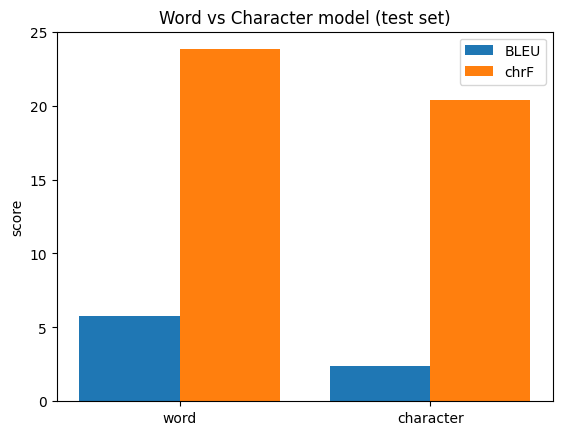

In [243]:
import matplotlib.pyplot as plt
import numpy as np

# word vs character model on the same test set (test_bleu / test_chrf come from the word model above)
print(f"word model -> BLEU {5.78:.2f}, chrF {23.81:.2f}")
print(f"char model -> BLEU {char_bleu:.2f}, chrF {char_chrf:.2f}")

labels = ["word", "character"]
bleus = [5.78, char_bleu]
chrfs = [23.81, char_chrf]

x = np.arange(len(labels))
plt.bar(x - 0.2, bleus, 0.4, label="BLEU")
plt.bar(x + 0.2, chrfs, 0.4, label="chrF")
plt.xticks(x, labels)
plt.ylabel("score")
plt.title("Word vs Character model (test set)")
plt.legend()
plt.show()